# EDA - llamadas 911 vs. red hidrografica (hl/ha)

Exploracion de `data/processed/llamadas_911/llamadas_911_hermosillo.csv` (4,176 registros 2018-2025, agrupados en 5 `grupo_incidente` por la seleccion manual de `features.py`) contra la red hidrografica INEGI (`hl` = cauces naturales, `ha` = cuerpos de agua, `dr` = puntos de drenaje) del consolidado `subc_hermosillo.gpkg`.

Hipotesis a explorar:

1. Hay menos llamadas de ciertos grupos de incidentes en zonas **sin** cauces.
2. Existe relacion temporal (temporada de lluvia) con las llamadas, **por grupo** - si los cauces se activan con lluvia, los incidentes relacionados deberian concentrarse en la temporada.
3. Habra zonas con cauces **sin** llamadas - ?drenaje bueno, o simplemente sin poblacion/colonias?

Caveats:

- Una fila = una llamada registrada; **no** hay id de evento - varias filas pueden ser llamadas del mismo incidente.
- `colonia` viene como texto libre del registro 911; se une al catalogo DCAH por nombre normalizado - los que no emparejen se reportan, no se descartan en silencio.
- `hl` es drenaje **natural** INEGI, no la red pluvial/sanitaria de la ciudad.
- Los sectores Norte/Centro/Sur vienen del CSV de experimentacion de la libreta 05 (bandas de latitud calibradas a mano).

In [1]:
import geopandas as gpd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from project_name.text import normalize_name

In [2]:
DATA = Path("../../data/processed")
SUBC = DATA / "inegi/hidrografia_hermosillo/subc_hermosillo.gpkg"
EXPERIMENT = Path("notebook_experimentation_data")

llamadas = pd.read_csv(DATA / "llamadas_911/llamadas_911_hermosillo.csv")
sectores = pd.read_csv(EXPERIMENT / "colonias_hermosillo.csv")
colonias = gpd.read_file(DATA / "aguah/colonias_hermosillo.gpkg")
hl = gpd.read_file(SUBC, layer="hl")
ha = gpd.read_file(SUBC, layer="ha")
dr = gpd.read_file(SUBC, layer="dr")

print(f"{len(llamadas)} llamadas | {llamadas['grupo_incidente'].nunique()} grupos")
print(f"{len(colonias)} colonias | hl: {len(hl)}, ha: {len(ha)}, dr: {len(dr)}")

4176 llamadas | 5 grupos
783 colonias | hl: 46518, ha: 744, dr: 36


## Preparacion

In [3]:
llamadas["fecha"] = pd.to_datetime(llamadas["fecha"])
llamadas["anio"] = llamadas["fecha"].dt.year
llamadas["mes"] = llamadas["fecha"].dt.month

print(llamadas["fecha"].min().date(), "->", llamadas["fecha"].max().date())
print()
print(llamadas["grupo_incidente"].value_counts().to_string())
print()
print(llamadas.groupby("anio").size().to_string())

2018-01-05 -> 2025-09-30

grupo_incidente
terreno                        2545
drenaje_y_red_de_agua          1066
inundacion_directa              454
ahogamiento_acuaticos            84
fenomeno_hidrometeorologico      27

anio
2018    504
2019    425
2020    231
2021    571
2022    825
2023    445
2024    538
2025    637


In [4]:
# sectores solo para la ciudad (locality_code "0001"); Kino y Miguel
# Aleman quedan fuera, como en la libreta 05. Ojo: en el CSV se lee como
# int (1), por eso el zfill
ciudad = sectores[sectores["locality_code"].astype(str).str.zfill(4) == "0001"].copy()

# normalizo ambos lados del join por nombre; colonia_id a str (el CSV lo
# lee como int y el gpkg lo trae como str)
ciudad["nombre_norm"] = ciudad["settlement_name"].map(normalize_name)
llamadas["nombre_norm"] = llamadas["colonia"].map(normalize_name)

catalogo = (
    ciudad[["colonia_id", "nombre_norm", "sector", "area_km2"]]
    .drop_duplicates("nombre_norm")
)
catalogo["colonia_id"] = catalogo["colonia_id"].astype(str)

llamadas = llamadas.merge(catalogo, on="nombre_norm", how="left")

con_sector = llamadas["sector"].notna()
print(f"{con_sector.sum()} / {len(llamadas)} llamadas unidas a colonia con sector")
sin = llamadas[~con_sector]["colonia"].value_counts()
print(f"\n{sin.shape[0]} nombres sin emparejar ({(~con_sector).sum()} llamadas):")
print(sin.head(30).to_string())

2923 / 4176 llamadas unidas a colonia con sector

294 nombres sin emparejar (1253 llamadas):
colonia
SIN COLONIA                          57
VILLA DE SERIS SUR                   38
HERMOSILLO CENTRO                    37
EL RANCHITO                          31
OLIVARES NORTE                       28
SONACER                              27
MIGUEL ALEMAN (LA DOCE)              26
SOLIDARIDAD V                        24
COLINAS DEL BACHOCO                  23
CENTRO BAHIA DE KINO                 21
HERMOSILLO                           19
SAN PEDRO EL SAUCITO                 17
BUGAMBILIAS                          17
LA MISION                            16
PRIVADA QUINTA EMILIA                15
COLONIA RURAL HERMOSILLO             15
FOVISSSTE                            14
TEC MILENIO                          14
PALMA DORADA                         14
LOS MIRASOLES                        13
PIEDRA BOLA (PEDREGAL DE LA VILLA    13
EUSEBIO KINO                         12
P. INDUSTRIAL      

El join por nombre cubre ~70% de las llamadas. Entre los sin emparejar hay nombres que no son colonia (`SIN COLONIA`, `HERMOSILLO`, `COLONIA RURAL HERMOSILLO`), localidades fuera de la ciudad (`CENTRO BAHIA DE KINO`, `MIGUEL ALEMAN`), y variantes del 911 que no existen en el catalogo (`VILLA DE SERIS SUR`, `OLIVARES NORTE`, `SOLIDARIDAD V`...). Quedan fuera del analisis por colonia/sector de esta seccion; el diccionario de equivalencias se genera al final de la libreta (`equivalencias_colonias_911.csv`) y, una vez revisado a mano, se aplica en la seccion de distancia a cauces.

In [5]:
METRICO = 6372  # Conica Conforme de Lambert ITRF2008, metros

colonias_m = colonias.to_crs(epsg=METRICO)
hl_m = hl.to_crs(epsg=METRICO)
ha_m = ha.to_crs(epsg=METRICO)

# recorto la red a las colonias de la ciudad para medir exposicion urbana
ciudad_ids = set(ciudad["colonia_id"].astype(str))
colonias_ciudad = colonias_m[colonias_m["colonia_id"].astype(str).isin(ciudad_ids)].copy()

hl_ciudad = gpd.clip(hl_m, colonias_ciudad)
ha_ciudad = gpd.clip(ha_m, colonias_ciudad)

print(f"{len(colonias_ciudad)} colonias de ciudad | hl recortada: {len(hl_ciudad)} tramos")
print(f"km de cauce dentro de colonias: {hl_ciudad.length.sum()/1000:.1f}")

762 colonias de ciudad | hl recortada: 437 tramos
km de cauce dentro de colonias: 188.6


In [6]:
# exposicion por colonia: km de cauce hl dentro de su poligono - se recorta
# hl por colonia y se suma la longitud real dentro del poligono
tramos = []
for _, c in colonias_ciudad.iterrows():
    clip = gpd.clip(hl_m, c.geometry)
    tramos.append({"colonia_id": c["colonia_id"], "km_cauce": clip.length.sum() / 1000})
info = ciudad[["colonia_id", "settlement_name", "sector", "area_km2"]].copy()
info["colonia_id"] = info["colonia_id"].astype(str)
expo = pd.DataFrame(tramos).merge(info, on="colonia_id", how="left")
expo["tiene_cauce"] = expo["km_cauce"] > 0

print(expo.groupby("tiene_cauce").size().rename("colonias").to_string())
print()
print(expo.groupby("sector")["km_cauce"].sum().round(1).to_string())

tiene_cauce
False    408
True     354

sector
Centro     11.4
Norte     112.4
Sur        64.7


## H1: ¿menos llamadas en zonas sin cauces?

Unidad de analisis: colonia. Comparo llamadas por colonia y por grupo entre colonias **con** cauce (`km_cauce > 0`) y **sin** cauce. Se normaliza por area (llamadas/km2) y por n de colonias - el conteo crudo engana porque las colonias sin cauce son mas y en promedio mas densas.

In [7]:
ll_col = (
    llamadas.dropna(subset=["colonia_id"])
    .groupby(["colonia_id", "grupo_incidente"]).size()
    .unstack(fill_value=0)
)
ll_col["llamadas"] = ll_col.sum(axis=1)

expo = expo.set_index("colonia_id").join(ll_col, how="left").reset_index()
expo[ll_col.columns] = expo[ll_col.columns].fillna(0)

resumen = expo.groupby("tiene_cauce").agg(
    colonias=("colonia_id", "size"),
    area_km2=("area_km2", "sum"),
    km_cauce=("km_cauce", "sum"),
    llamadas=("llamadas", "sum"),
).rename(index={False: "sin cauce", True: "con cauce"})
resumen["llamadas_por_colonia"] = resumen["llamadas"] / resumen["colonias"]
resumen["llamadas_por_km2"] = resumen["llamadas"] / resumen["area_km2"]
resumen.round(2)

,colonias,area_km2,km_cauce,llamadas,llamadas_por_colonia,llamadas_por_km2
tiene_cauce,,,,,,
sin cauce,408,57.15,0.00,1574.0,3.86,27.54
con cauce,354,75.29,188.56,1349.0,3.81,17.92


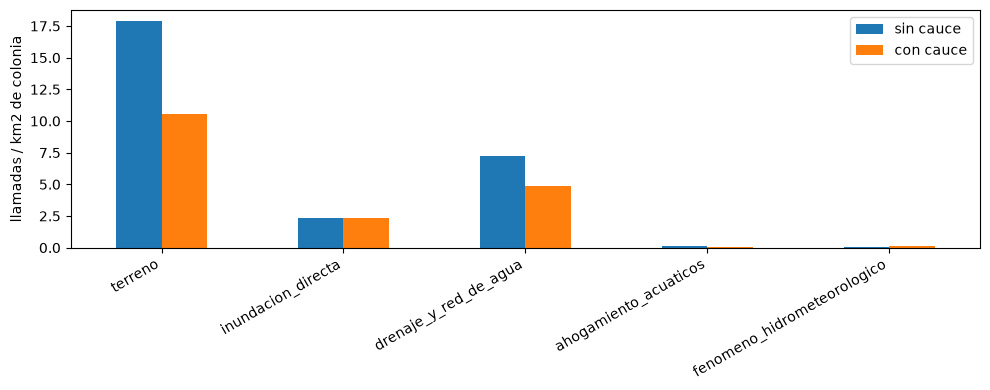

,terreno,inundacion_directa,drenaje_y_red_de_agua,ahogamiento_acuaticos,fenomeno_hidrometeorologico
sin cauce,17.87,2.31,7.21,0.12,0.03
con cauce,10.59,2.32,4.83,0.03,0.15


In [8]:
# desglose por grupo: llamadas por km2 de colonia, con vs. sin cauce
grupos = llamadas["grupo_incidente"].unique().tolist()
tabla = expo.groupby("tiene_cauce")[grupos + ["area_km2"]].sum()
por_km2 = tabla[grupos].div(tabla["area_km2"], axis=0).round(2)
por_km2.index = ["sin cauce", "con cauce"]
por_km2.T.plot.bar(figsize=(10, 4))
plt.ylabel("llamadas / km2 de colonia")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()
por_km2

**Lectura:** si la H1 fuera cierta, los grupos ligados a agua en superficie (`inundacion_directa`, `fenomeno_hidrometeorologico`) tendrian tasas por km2 claramente menores en colonias sin cauce. Ojo: `drenaje_y_red_de_agua` es infraestructura urbana - no deberia depender de `hl`; sirve casi de control.

## ¿relacion temporal con temporada de lluvia, por grupo?

Definicion operativa: **meses de lluvia = agosto, septiembre, octubre** (temporada de monzon en Hermosillo; constante editable abajo). Como son 8 anos, comparo el promedio mensual por ano para no sesgar por anos con distinta cobertura.

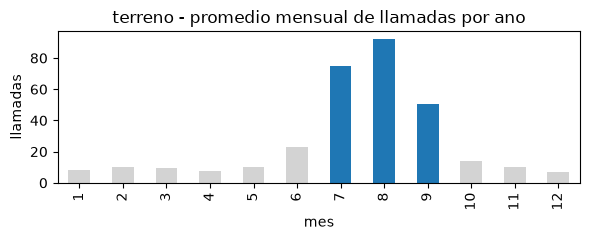

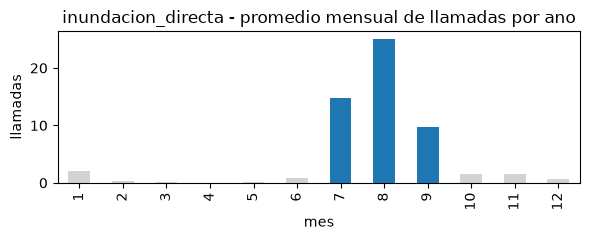

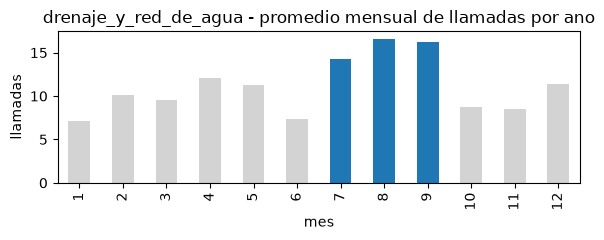

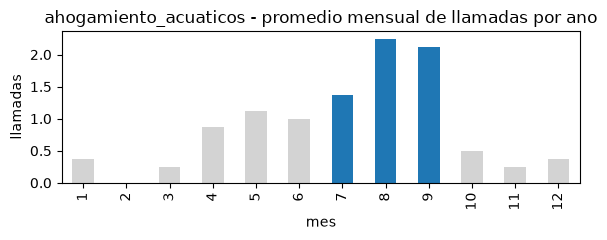

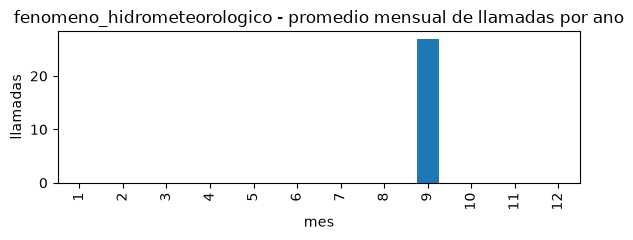

In [9]:
MESES_LLUVIA = [7,8, 9]
llamadas["lluvia"] = llamadas["mes"].isin(MESES_LLUVIA)

# promedio de llamadas por mes dentro de cada anio, por grupo
for g in grupos:
    sub = llamadas[llamadas["grupo_incidente"] == g]
    mensual = sub.groupby(["anio", "mes"]).size().unstack(fill_value=0)
    promedio = mensual.sum().reindex(range(1, 13), fill_value=0) / max(len(mensual), 1)
    fig, ax = plt.subplots(figsize=(6, 2.5))
    colores = ["tab:blue" if m in MESES_LLUVIA else "lightgray" for m in promedio.index]
    promedio.plot.bar(ax=ax, color=colores)
    ax.set_title(f"{g} - promedio mensual de llamadas por ano")
    ax.set_ylabel("llamadas")
    plt.tight_layout()
    plt.show()

In [10]:
temp = (
    llamadas.groupby(["grupo_incidente", "lluvia"])
    .size().unstack(fill_value=0)
    .rename(columns={False: "no_lluvia", True: "lluvia"})
)
# normalizo: los meses de lluvia son 3 de 12, asi que a igualdad esperada = 25%
temp["total"] = temp.sum(axis=1)
temp["pct_lluvia"] = (temp["lluvia"] / temp["total"] * 100).round(1)
temp.sort_values("pct_lluvia", ascending=False)

lluvia,no_lluvia,lluvia,total,pct_lluvia
grupo_incidente,,,,
fenomeno_hidrometeorologico,0,27,27,100.0
inundacion_directa,57,397,454,87.4
terreno,803,1742,2545,68.4
ahogamiento_acuaticos,38,46,84,54.8
drenaje_y_red_de_agua,689,377,1066,35.4


**Lectura:** 25% es el valor esperado si las llamadas fueran uniformes en el ano. Los grupos que superan ~30-35% concentran en temporada. Es asociacion temporal, **no** prueba causal - sin datos de precipitacion no se puede atar cada llamada a un evento de lluvia.

## ¿zonas con cauces sin llamadas?

Busco colonias con `km_cauce > 0` y cero llamadas (?drenaje bueno o sin poblacion?) y colonias **sin** cauce con muchas llamadas (?el agua no viene del cauce sino de la red urbana?). No hay dato de poblacion en los archivos - la hipotesis 'sin poblacion' queda **sin verificar**; el poligono existe pero no sabemos si esta habitado.

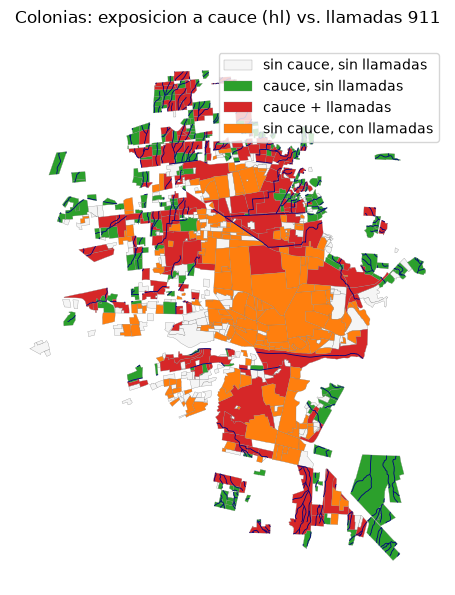

cat
sin cauce, sin llamadas    235
cauce, sin llamadas        197
sin cauce, con llamadas    173
cauce + llamadas           157

      settlement_name sector  llamadas  area_km2
           San Benito Centro     120.0    2.5129
             Olivares Centro      75.0    1.8018
               Centro Centro      73.0    2.1299
           Centenario Centro      55.0    0.6973
         Constitución Centro      45.0    0.3357
               Choyal  Norte      40.0    0.6267
            5 de Mayo Centro      36.0    0.4121
Fuentes del Mezquital Centro      36.0    0.3194
          Las Granjas Centro      36.0    0.4645
             Pimentel Centro      36.0    0.5937
          Las Quintas Centro      35.0    0.4148
               Modelo Centro      32.0    1.0796
   Primero Hermosillo  Norte      31.0    0.2171
        Jacinto López  Norte      26.0    0.7453
       Miguel Hidalgo  Norte      26.0    0.5458


In [11]:
fig, ax = plt.subplots(figsize=(10, 7))
col_g = colonias_ciudad.merge(
    expo[["colonia_id", "km_cauce", "llamadas", "sector"]],
    on="colonia_id", how="left",
)
col_g["cat"] = "sin cauce, sin llamadas"
col_g.loc[(col_g["km_cauce"] > 0) & (col_g["llamadas"].fillna(0) == 0), "cat"] = "cauce, sin llamadas"
col_g.loc[(col_g["km_cauce"] > 0) & (col_g["llamadas"].fillna(0) > 0), "cat"] = "cauce + llamadas"
col_g.loc[(col_g["km_cauce"] == 0) & (col_g["llamadas"].fillna(0) > 0), "cat"] = "sin cauce, con llamadas"

paleta = {
    "sin cauce, sin llamadas": "whitesmoke",
    "cauce, sin llamadas": "tab:green",
    "cauce + llamadas": "tab:red",
    "sin cauce, con llamadas": "tab:orange",
}
for cat, color in paleta.items():
    col_g[col_g["cat"] == cat].plot(ax=ax, color=color, edgecolor="gray",
                                    linewidth=0.2, label=cat)
hl_ciudad.plot(ax=ax, color="navy", linewidth=0.6)
ax.legend()
ax.set_axis_off()
ax.set_title("Colonias: exposicion a cauce (hl) vs. llamadas 911")
plt.show()

print(col_g["cat"].value_counts().to_string())
print()
top_sin_cauce = col_g[col_g["cat"] == "sin cauce, con llamadas"].nlargest(15, "llamadas")
print(top_sin_cauce[["settlement_name", "sector", "llamadas", "area_km2"]].to_string(index=False))

In [12]:
# el otro extremo: colonias CON cauce pero sin llamadas
cauce_sin = col_g[col_g["cat"] == "cauce, sin llamadas"]
print(f"{len(cauce_sin)} colonias con cauce y 0 llamadas:")
print(cauce_sin[["settlement_name", "sector", "km_cauce", "area_km2"]]
      .sort_values("km_cauce", ascending=False).head(35).to_string(index=False))

197 colonias con cauce y 0 llamadas:
                        settlement_name sector  km_cauce  area_km2
        Parque Industrial de Hermosillo    Sur  9.258687    4.4937
                           Dynatech Sur    Sur  5.336698    1.1668
                           Café Combate  Norte  2.311631    0.5601
                  Miniparque Industrial  Norte  1.868171    0.2136
            Parque Industrial de Sonora    Sur  1.582437    0.4198
              Finca Las Riberas Etapa I  Norte  1.510736    0.3785
                       Privadas del Rey  Norte  1.481577    0.2624
                   Río Seco Residencial  Norte  1.444198    0.2432
               Bicentenario Residencial  Norte  1.274973    0.2617
                     Central de Abastos    Sur  1.209251    0.2891
                  Arándanos Residencial  Norte  1.182810    0.2002
                    Altaria Residencial  Norte  1.120841    0.3135
                             Las Cuevas  Norte  1.108606    0.4378
                         

- Sin precipitacion ni poblacion, las relaciones son asociativas, no causales.

## Distancia a los 3 cauces mas cercanos

Las llamadas no traen coordenadas - solo el nombre de colonia - asi que la distancia se mide desde el **centroide de la colonia emparejada** (EPSG:6372, metros). "Cauce" = tramo individual de `hl`; los 3 mas cercanos pueden ser tramos del mismo arroyo. El calculo se hace una vez por colonia y se propaga a todas sus llamadas: `1er_cauce`, `2do_cauce`, `3er_cauce` son propiedad de la **colonia**, no de la llamada individual.

Junto a cada distancia se guarda el **orden de Strahler** del tramo (`orden_1er_cauce`, `orden_2do_cauce`, `orden_3er_cauce`): `1` = cauce de cabecera, `>=4` = colector principal, `-1` = tramo sin clasificar - para cruzar volumen de llamadas con cercania a cauces mayores.

Antes del calculo se aplican las equivalencias revisadas a mano en `notebook_experimentation_data/equivalencias_colonias_911.csv` (columna `OK` = nombre del catalogo; vacio o `NA` = sin definir), que rescatan llamadas cuya colonia no emparejo en el join por `nombre_norm`.

In [13]:
# equivalencias revisadas a mano: OK = nombre del catalogo correspondiente
# a la colonia del 911; vacio o "NA" = no se pudo definir
eq = pd.read_csv(EXPERIMENT / "equivalencias_colonias_911.csv")
ok = eq[["colonia_911", "OK"]].dropna()
ok = ok[ok["OK"].astype(str).str.strip().str.upper() != "NA"].copy()
ok["nombre_eq"] = ok["OK"].map(normalize_name)

# el nombre elegido debe existir en el catalogo; los que no, se reportan
resueltas = ok.merge(
    catalogo, left_on="nombre_eq", right_on="nombre_norm", how="left"
)
sin_resolver = resueltas[resueltas["colonia_id"].isna()]
if len(sin_resolver):
    print(f"{len(sin_resolver)} equivalencias no estan en el catalogo (revisar el CSV):")
    print(sin_resolver[["colonia_911", "OK"]].to_string(index=False))

lookup = resueltas.dropna(subset=["colonia_id"]).set_index("colonia_911")

# se rellenan solo los campos que quedaron NaN en el join por nombre_norm
antes = llamadas["colonia_id"].isna()
for col in ["colonia_id", "sector", "area_km2"]:
    llamadas[col] = llamadas[col].fillna(llamadas["colonia"].map(lookup[col]))

print(f"{int(antes.sum() - llamadas['colonia_id'].isna().sum())} llamadas "
      "recuperadas por equivalencias")
print(f"{int(llamadas['colonia_id'].isna().sum())} llamadas siguen sin colonia")

622 llamadas recuperadas por equivalencias
631 llamadas siguen sin colonia


In [14]:
# red candidata: tramos hl dentro de 5 km de la ciudad - medir contra los
# 46,518 tramos de las subcuencas da el mismo resultado pero es ~30x mas lento
BUFFER_M = 5000
zona = colonias_ciudad.union_all().buffer(BUFFER_M)
hl_cerca = hl_m[hl_m.intersects(zona)]
print(f"{len(hl_cerca)} tramos hl dentro de {BUFFER_M / 1000:.0f} km de la ciudad")

# un centroide por colonia que aparece en llamadas
ids_llamadas = llamadas["colonia_id"].dropna().unique()
centroides = (
    colonias_ciudad.set_index("colonia_id")
    .loc[lambda d: d.index.isin(ids_llamadas)]
    .geometry.centroid
)
print(f"{len(centroides)} colonias con llamadas emparejadas")

ORDEN = ["orden_1er_cauce", "orden_2do_cauce", "orden_3er_cauce"]


def tres_mas_cercanos(punto):
    # distancia y orden de Strahler (ORDER_1) de los 3 tramos mas cercanos;
    # ORDER_1 = -1 en tramos sin clasificar
    dist = hl_cerca.geometry.distance(punto).to_numpy()
    idx = np.argsort(dist)[:3]
    return pd.Series(
        np.concatenate([dist[idx], hl_cerca["ORDER_1"].to_numpy()[idx]]),
        index=["1er_cauce", "2do_cauce", "3er_cauce"] + ORDEN,
    )


dist_col = centroides.apply(tres_mas_cercanos)
dist_col[ORDEN] = dist_col[ORDEN].astype("Int64")

# chequeos: orden por construccion y que el buffer no corte el 3er cauce
assert (dist_col["1er_cauce"] <= dist_col["2do_cauce"]).all()
assert (dist_col["2do_cauce"] <= dist_col["3er_cauce"]).all()
lejos = dist_col["3er_cauce"] >= BUFFER_M
if lejos.any():
    print(f"ojo: {lejos.sum()} colonias con 3er cauce a >{BUFFER_M / 1000:.0f} km"
          " - el buffer podria estar cortando su verdadero 3er cauce")

dist_col.describe().round(0)

1932 tramos hl dentro de 5 km de la ciudad
396 colonias con llamadas emparejadas


,1er_cauce,2do_cauce,3er_cauce,orden_1er_cauce,orden_2do_cauce,orden_3er_cauce
count,396.0,396.0,396.0,396.0,396.0,396.0
mean,420.0,623.0,799.0,2.0,2.0,2.0
std,438.0,529.0,667.0,1.0,1.0,1.0
min,1.0,26.0,26.0,-1.0,-1.0,-1.0
25%,109.0,208.0,294.0,1.0,1.0,1.0
50%,254.0,466.0,615.0,1.0,1.0,1.0
75%,583.0,887.0,1070.0,2.0,2.0,2.0
max,2188.0,2702.0,3192.0,4.0,4.0,4.0


In [15]:
llamadas_cauces = llamadas.merge(
    dist_col, left_on="colonia_id", right_index=True, how="left"
)

con_dist = llamadas_cauces["1er_cauce"].notna()
print(f"{len(llamadas_cauces)} filas | con distancia: {con_dist.sum()} "
      f"| sin colonia emparejada (NaN): {(~con_dist).sum()}")
llamadas_cauces[dist_col.columns].describe().round(0)

4176 filas | con distancia: 3545 | sin colonia emparejada (NaN): 631


,1er_cauce,2do_cauce,3er_cauce,orden_1er_cauce,orden_2do_cauce,orden_3er_cauce
count,3545.0,3545.0,3545.0,3545.0,3545.0,3545.0
mean,646.0,887.0,1147.0,2.0,2.0,2.0
std,571.0,652.0,815.0,1.0,1.0,1.0
min,1.0,26.0,26.0,-1.0,-1.0,-1.0
25%,199.0,356.0,414.0,1.0,1.0,1.0
50%,453.0,761.0,922.0,1.0,1.0,1.0
75%,1005.0,1343.0,1854.0,2.0,2.0,3.0
max,2188.0,2702.0,3192.0,4.0,4.0,4.0


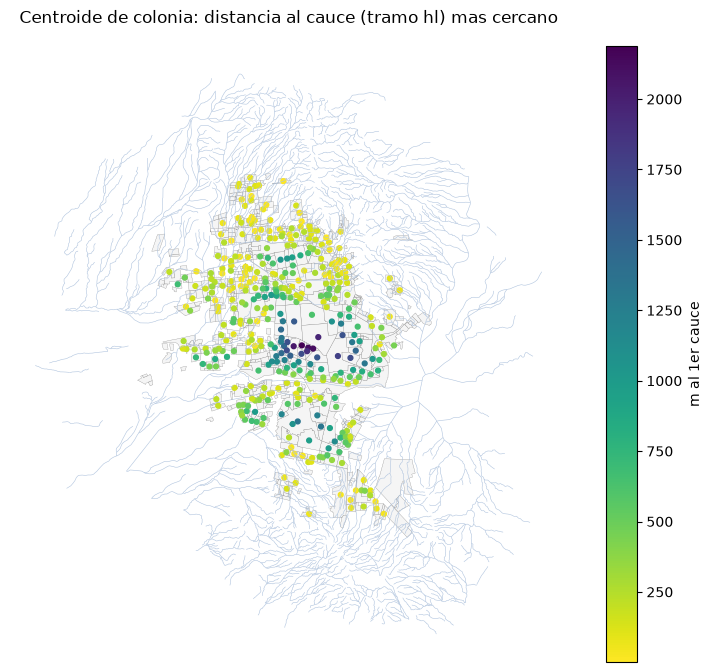

In [16]:
# chequeo visual: centroides coloreados por distancia al 1er cauce sobre la red
fig, ax = plt.subplots(figsize=(10, 8))
colonias_ciudad.plot(ax=ax, color="whitesmoke", edgecolor="gray", linewidth=0.2)
hl_cerca.plot(ax=ax, color="lightsteelblue", linewidth=0.4)
gpd.GeoDataFrame(dist_col, geometry=centroides, crs=hl_m.crs).plot(
    ax=ax, column="1er_cauce", cmap="viridis_r", markersize=12, legend=True,
    legend_kwds={"label": "m al 1er cauce"},
)
ax.set_axis_off()
ax.set_title("Centroide de colonia: distancia al cauce (tramo hl) mas cercano")
plt.show()

## Colonias del 911 sin emparejar - equivalencias para revision

`notebook_experimentation_data/equivalencias_colonias_911.csv` lista los nombres de colonia del 911 sin emparejar con hasta 3 nombres del catalogo DCAH similares (`difflib`); la columna `OK` se lleno a mano con el nombre correcto (vacio o `NA` = sin definir) y ya se aplica arriba sobre `llamadas`. La celda siguiente **no sobreescribe** el archivo - solo lo genera si no existe, para no borrar la revision manual.

In [17]:
import difflib

# nombres 911 sin emparejar -> 3 candidatos del catalogo por similitud;
# la columna OK se llena a mano con el nombre correcto (vacio o "NA" si no
# se puede definir) y se aplica en la seccion de distancia a cauces
sin_match = llamadas.loc[llamadas["colonia_id"].isna(), "colonia"].value_counts()

# nombre normalizado -> nombre legible del catalogo
legible = (
    ciudad.drop_duplicates("nombre_norm")
    .set_index("nombre_norm")["settlement_name"]
)
catalogo_norm = sorted(legible.index)

filas = []
for nombre, n in sin_match.items():
    sugeridas = difflib.get_close_matches(
        normalize_name(nombre), catalogo_norm, n=3, cutoff=0.55
    )
    fila = {"colonia_911": nombre, "n_llamadas": n}
    for i in range(3):
        fila[f"sugerencia_{i + 1}"] = (
            legible[sugeridas[i]] if i < len(sugeridas) else ""
        )
    fila["OK"] = ""
    filas.append(fila)

eq = pd.DataFrame(filas).sort_values("n_llamadas", ascending=False)
ruta_eq = EXPERIMENT / "equivalencias_colonias_911.csv"
if ruta_eq.exists():
    # el archivo ya trae la revision manual en OK; no se sobreescribe
    print(f"{ruta_eq} ya existe - se conserva la revision manual")
else:
    eq.to_csv(ruta_eq, index=False)
    print(f"{len(eq)} nombres sin emparejar -> {ruta_eq}")
eq.head(15)

notebook_experimentation_data\equivalencias_colonias_911.csv ya existe - se conserva la revision manual


,colonia_911,n_llamadas,sugerencia_1,sugerencia_2,sugerencia_3,OK
0,SIN COLONIA,57,Villa Colonial,Villa California,Sierra Bonita,
1,MIGUEL ALEMAN (LA DOCE),26,Miguel Hidalgo,,,
2,COLINAS DEL BACHOCO,23,Colina Blanca,Lomas de Barrocan,Colinas de San Javier,
3,CENTRO BAHIA DE KINO,21,Cerrada de Minas,Central de Abastos,,
4,HERMOSILLO,19,Nuevo Hermosillo,Primero Hermosillo,Heberto Castillo,
5,SAN PEDRO EL SAUCITO,17,Misión del Arco,San Jerónimo,San Bosco,
6,BUGAMBILIAS,17,Bugambilia,Prados de Bugambilias,Prados de Bugambilias II,
7,COLONIA RURAL HERMOSILLO,15,Nuevo Hermosillo,Primero Hermosillo,,
8,TEC MILENIO,14,El Malecón,,,
9,PALMA DORADA,14,Villa Dorada,Alborada,Valle Dorado,


## EDA: distancias a los 3 cauces

Tres preguntas sobre `1er_cauce`/`2do_cauce`/`3er_cauce` en `llamadas_cauces`:

1. ¿Hay relacion con el grupo de incidente? (los grupos ligados a agua en superficie deberian estar mas cerca de los cauces si la señal es real)
2. ¿Algun sector tiene menores distancias promedio?
3. ¿Las colonias con mas llamadas estan mas cerca - o mas lejos - de los cauces?

Caveat: las 3 distancias son propiedad de la **colonia** y se repiten en todas sus llamadas - los grupos/sectores con muchas llamadas en pocas colonias pesan mas. Por eso las pruebas sobre llamadas individuales exageran la significancia: leer las diferencias por magnitud, no por p-valor.

In [18]:
DIST = ["1er_cauce", "2do_cauce", "3er_cauce"]
con_dist = llamadas_cauces.dropna(subset=["1er_cauce"])
print(f"{len(con_dist)} llamadas con distancia "
      f"({con_dist['colonia_id'].nunique()} colonias)")

# mediana de cada distancia por grupo de incidente
por_grupo = con_dist.groupby("grupo_incidente")[DIST].median().round(0)
por_grupo["llamadas"] = con_dist["grupo_incidente"].value_counts()
por_grupo["colonias"] = con_dist.groupby("grupo_incidente")["colonia_id"].nunique()
por_grupo.sort_values("1er_cauce")

3545 llamadas con distancia (396 colonias)


,1er_cauce,2do_cauce,3er_cauce,llamadas,colonias
grupo_incidente,,,,,
fenomeno_hidrometeorologico,168.0,291.0,313.0,18,16
inundacion_directa,338.0,685.0,776.0,366,140
drenaje_y_red_de_agua,408.0,647.0,861.0,942,229
terreno,499.0,791.0,1013.0,2207,354
ahogamiento_acuaticos,764.0,800.0,901.0,12,12


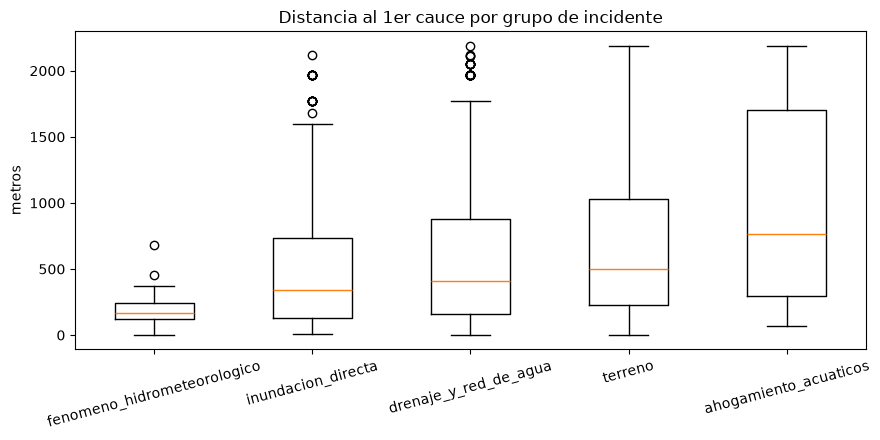

Kruskal-Wallis (1er_cauce ~ grupo): H=39.9, p=4.53e-08


In [19]:
fig, ax = plt.subplots(figsize=(9, 4.5))
orden = por_grupo.sort_values("1er_cauce").index
datos = [con_dist.loc[con_dist["grupo_incidente"] == g, "1er_cauce"] for g in orden]
ax.boxplot(datos, tick_labels=orden, showfliers=True)
ax.set_ylabel("metros")
ax.set_title("Distancia al 1er cauce por grupo de incidente")
ax.tick_params(axis="x", labelrotation=15)
plt.tight_layout()
plt.show()

from scipy.stats import kruskal
H, p = kruskal(*datos)
print(f"Kruskal-Wallis (1er_cauce ~ grupo): H={H:.1f}, p={p:.3g}")

**Lectura:** `fenomeno_hidrometeorologico` (mediana 168 m al 1er cauce) e `inundacion_directa` (338 m) son los grupos **mas cercanos** a los cauces, por debajo de `terreno` (499 m), que funciona como control. `drenaje_y_red_de_agua` (408 m) va en medio - coherente con que es infraestructura urbana, no cauce natural. La excepcion es `ahogamiento_acuaticos` (764 m): 72 de sus 84 llamadas son de Bahia de Kino / Miguel Aleman (sin colonia de ciudad) y las 12 que si se mapean tampoco estan cerca - el ahogamiento no pasa en cauces `hl` sino en cuerpos de agua (`ha`) o playa; conviene mirarlo contra `ha` si interesa. Kruskal-Wallis dice que las distribuciones difieren, pero con el caveat de independencia de arriba; la lectura valida es por magnitud: ~150-330 m de diferencia entre el grupo mas cercano y el control, dentro de una ciudad donde todo esta a <1 km de algun cauce.

        1er_cauce_mean  1er_cauce_median  2do_cauce_mean  2do_cauce_median  3er_cauce_mean  3er_cauce_median  llamadas  colonias
sector                                                                                                                          
Centro          1030.0             962.0          1340.0            1434.0          1659.0            1781.0      1428       105
Norte            346.0             265.0           489.0             445.0           684.0             529.0      1450       199
Sur              478.0             357.0           782.0             717.0          1059.0            1023.0       667        92


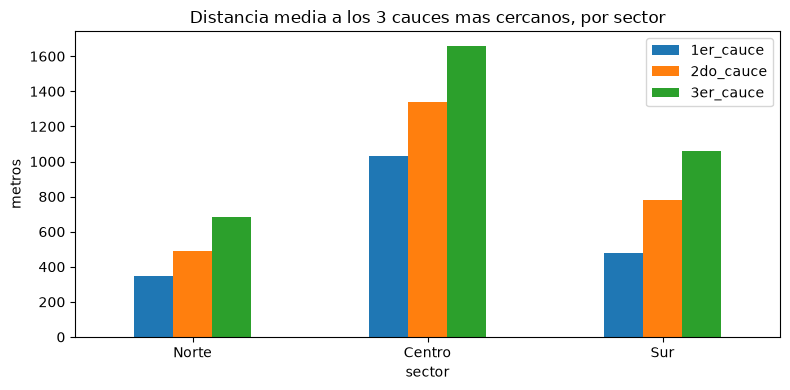

In [20]:
resumen_sector = con_dist.groupby("sector")[DIST].agg(["mean", "median"]).round(0)
resumen_sector.columns = [f"{d}_{m}" for d, m in resumen_sector.columns]
resumen_sector["llamadas"] = con_dist["sector"].value_counts()
resumen_sector["colonias"] = con_dist.groupby("sector")["colonia_id"].nunique()
print(resumen_sector.to_string())

fig, ax = plt.subplots(figsize=(8, 4))
con_dist.groupby("sector")[DIST].mean().reindex(["Norte", "Centro", "Sur"]).plot.bar(
    ax=ax, rot=0
)
ax.set_ylabel("metros")
ax.set_title("Distancia media a los 3 cauces mas cercanos, por sector")
plt.tight_layout()
plt.show()

        area_km2  km_cauce  km_cauce_por_km2  llamadas  llamadas_por_km2
sector                                                                  
Centro      36.9      11.4               0.3      1428              38.7
Norte       55.6     112.4               2.0      1450              26.1
Sur         40.0      64.7               1.6       667              16.7


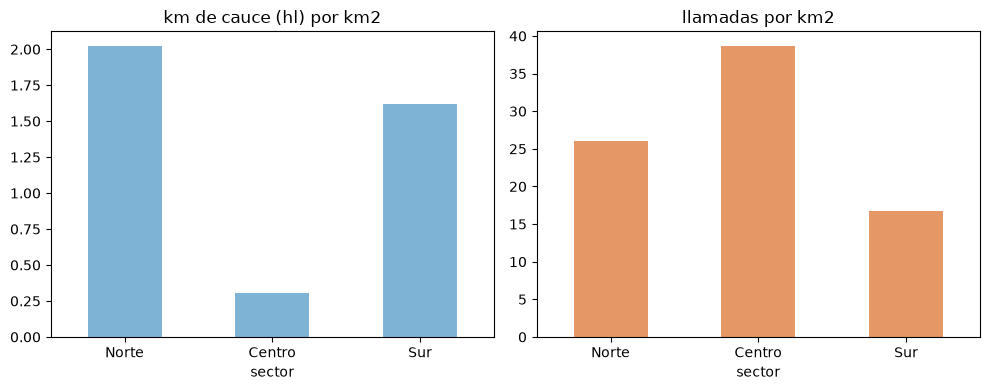

In [21]:
# comparativo por sector como en la libreta 06: km de cauce por km2 vs.
# llamadas por km2 (conteo de con_dist, ya con las equivalencias aplicadas)
sector_area = (
    expo.dropna(subset=["sector"])
    .groupby("sector")
    .agg(area_km2=("area_km2", "sum"), km_cauce=("km_cauce", "sum"))
)
sector_area["km_cauce_por_km2"] = sector_area["km_cauce"] / sector_area["area_km2"]
sector_area["llamadas"] = con_dist["sector"].value_counts()
sector_area["llamadas_por_km2"] = sector_area["llamadas"] / sector_area["area_km2"]
print(sector_area.round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sector_area["km_cauce_por_km2"].reindex(["Norte", "Centro", "Sur"]).plot.bar(
    ax=axes[0], rot=0, color="#7fb3d5"
)
axes[0].set_title("km de cauce (hl) por km2")
sector_area["llamadas_por_km2"].reindex(["Norte", "Centro", "Sur"]).plot.bar(
    ax=axes[1], rot=0, color="#e59866"
)
axes[1].set_title("llamadas por km2")
plt.tight_layout()
plt.show()

**Lectura:** si, y por mucho. **Norte** tiene las menores distancias medias (346 / 489 / 684 m) - es el sector con mas km de cauce en sus colonias (112 km, seccion de exposicion). **Sur** va en medio (478 / 782 / 1,059 m). **Centro** esta ~3x mas lejos (1,030 / 1,340 / 1,659 m) - la misma conclusion de la libreta 06: el Centro es ajeno a la red `hl` (solo 11 km de cauce en sus colonias). Ojo con interpretar: el Centro tambien concentra mas llamadas por colonia (~13.6 vs ~7), asi que "las llamadas estan lejos de los cauces" y "las llamadas estan en el Centro" son la misma observacion vista de dos lados.

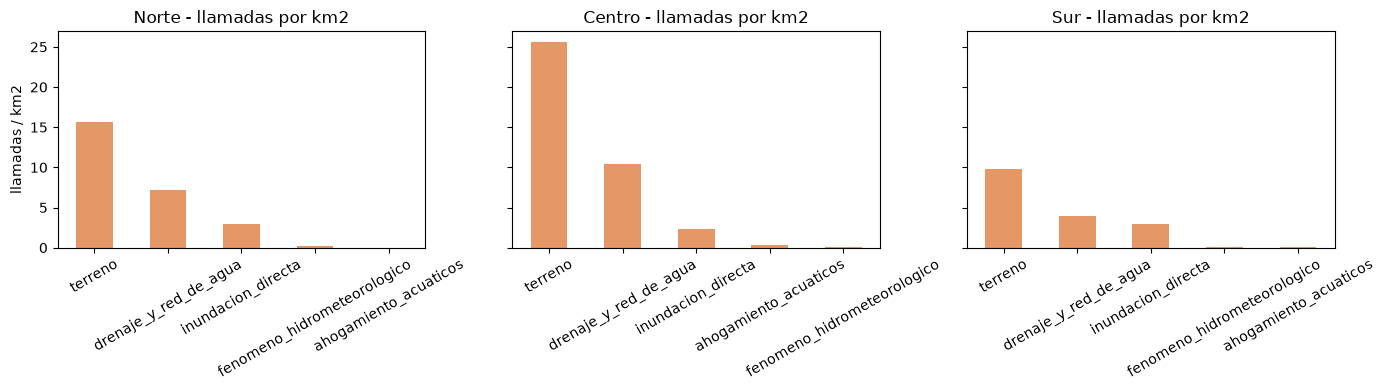

In [22]:
# llamadas por km2 por grupo de incidente dentro de cada sector
den_sector = (
    con_dist.groupby(["sector", "grupo_incidente"]).size()
    .unstack(fill_value=0)
    .div(sector_area["area_km2"], axis=0)
)

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, s in zip(axes, ["Norte", "Centro", "Sur"]):
    den_sector.loc[s].sort_values(ascending=False).plot.bar(
        ax=ax, rot=30, color="#e59866"
    )
    ax.set_title(f"{s} - llamadas por km2")
    ax.set_xlabel("")
axes[0].set_ylabel("llamadas / km2")
plt.tight_layout()
plt.show()

Top-3 por sector: {'Centro': ['terreno', 'drenaje_y_red_de_agua', 'inundacion_directa'], 'Norte': ['terreno', 'drenaje_y_red_de_agua', 'inundacion_directa'], 'Sur': ['terreno', 'drenaje_y_red_de_agua', 'inundacion_directa']}


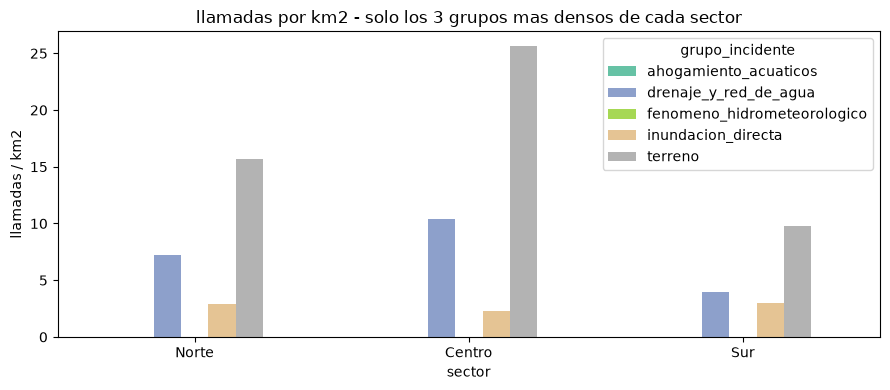

In [23]:
# los 3 grupos mas densos de cada sector y la tabla filtrada
top3 = {s: den_sector.loc[s].nlargest(3).index.tolist() for s in den_sector.index}
print("Top-3 por sector:", top3)

# NaN fuera del top-3 de su sector: cada cluster muestra solo sus 3 elegidos
den_top3 = den_sector.copy()
for s, grupos in top3.items():
    den_top3.loc[s, ~den_top3.columns.isin(grupos)] = np.nan

den_top3.reindex(["Norte", "Centro", "Sur"]).plot.bar(
    figsize=(9, 4), rot=0, colormap="Set2"
)
plt.ylabel("llamadas / km2")
plt.title("llamadas por km2 - solo los 3 grupos mas densos de cada sector")
plt.tight_layout()
plt.show()

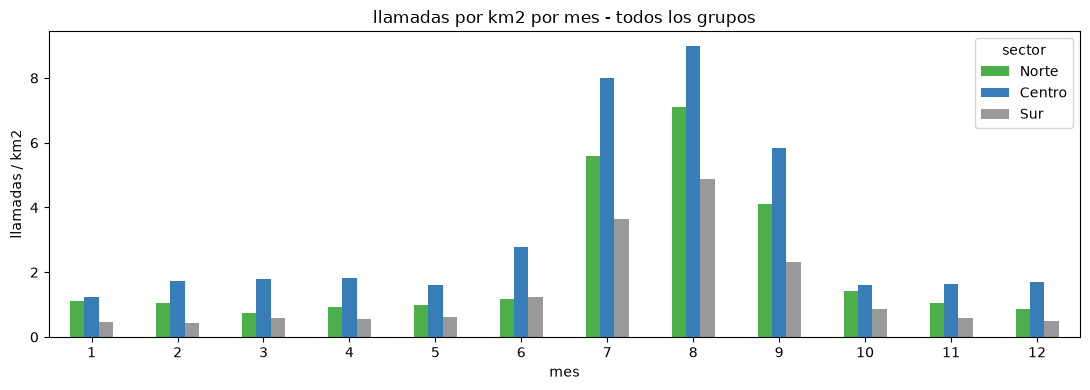

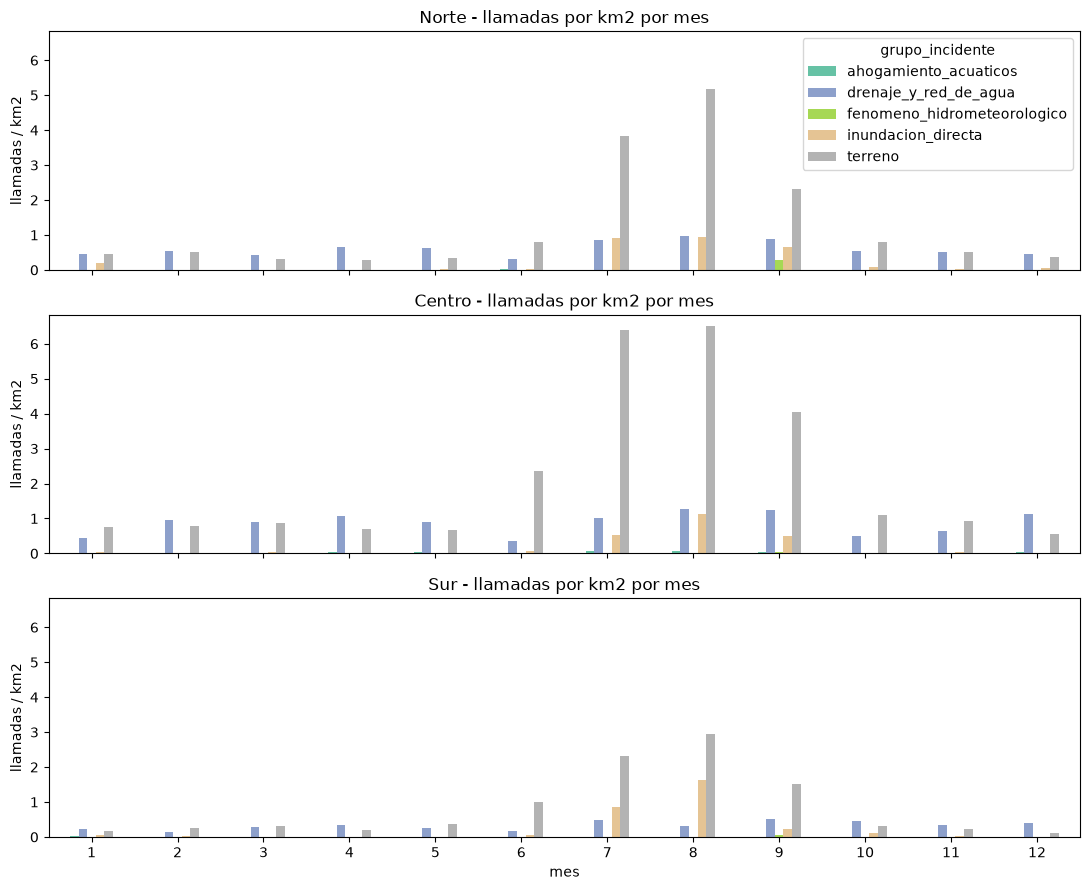

In [24]:
# llamadas por km2 por mes - TODOS los grupo_incidente
orden_sectores = ["Norte", "Centro", "Sur"]

mes_sector_todos = (
    con_dist.groupby(["mes", "sector"]).size()
    .unstack(fill_value=0)
    .reindex(range(1, 13), fill_value=0)
)

# mes en el eje x, un color por sector
(mes_sector_todos / sector_area["area_km2"]).reindex(
    columns=orden_sectores
).plot.bar(
    figsize=(11, 4), rot=0,
    color=["#4daf4a", "#377eb8", "#999999"],
)
plt.xlabel("mes")
plt.ylabel("llamadas / km2")
plt.title("llamadas por km2 por mes - todos los grupos")
plt.legend(title="sector")
plt.tight_layout()
plt.show()

# una fila por sector: mes en el eje x, un color por grupo_incidente (los 5)
mes_sector_grupo_todos = (
    con_dist.groupby(["mes", "sector", "grupo_incidente"]).size()
    .unstack(fill_value=0)
)
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True, sharey=True)
for ax, s in zip(axes, orden_sectores):
    d = mes_sector_grupo_todos.xs(s, level="sector").reindex(
        range(1, 13), fill_value=0
    )
    (d / sector_area.loc[s, "area_km2"]).plot.bar(
        ax=ax, rot=0, colormap="Set2", legend=ax is axes[0]
    )
    ax.set_title(f"{s} - llamadas por km2 por mes")
    ax.set_ylabel("llamadas / km2")
axes[-1].set_xlabel("mes")
axes[0].legend(title="grupo_incidente")
plt.tight_layout()
plt.show()

### Solo grupos de superficie

Se repite el análisis de densidad filtrando a los grupos ligados a agua en superficie: `inundacion_directa` y `fenomeno_hidrometeorologico`.

`ahogamiento_acuaticos` se descarto: ~51% de sus llamadas son accidentes en la costa (Bahia de Kino / Miguel Aleman — la capa relevante es `ha`, no la red `hl`), 11 son SIN COLONIA y el resto se reparte en ~30 colonias urbanas sin concentracion — ruido para este analisis.

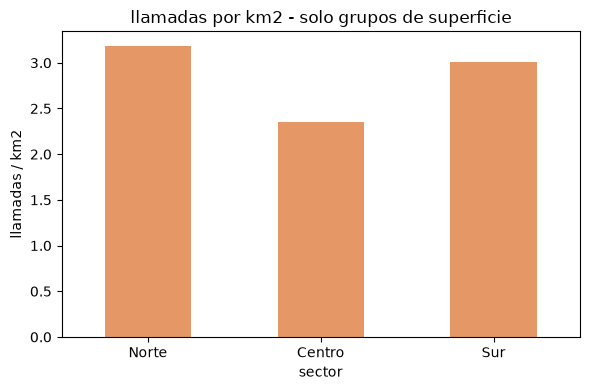

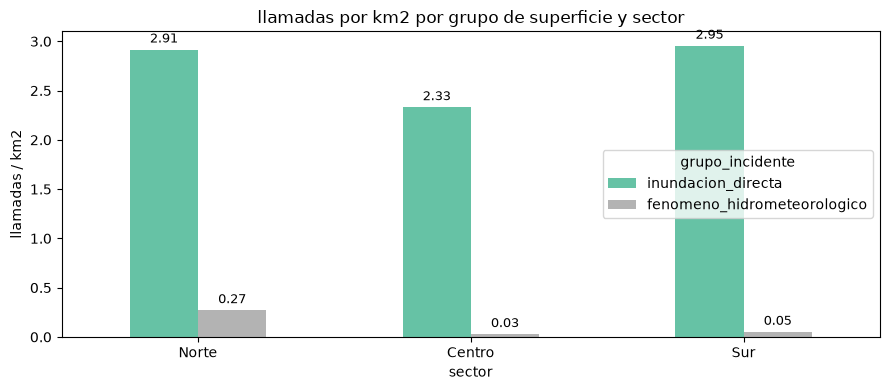

In [25]:
# solo los grupos ligados a agua en superficie.
# ahogamiento_acuaticos se excluye: ~51% de sus llamadas son accidentes
# en la costa (Bahia de Kino / Miguel Aleman -> capa ha, no red hl) y el
# resto esta disperso en ~30 colonias sin hotspot - ruido para este analisis
GRUPOS_AGUA = [
    "inundacion_directa", "fenomeno_hidrometeorologico",
]

# llamadas por km2 sumando los 2 grupos, por sector
den_agua = den_sector[GRUPOS_AGUA].sum(axis=1)
den_agua.reindex(["Norte", "Centro", "Sur"]).plot.bar(
    figsize=(6, 4), rot=0, color="#e59866"
)
plt.ylabel("llamadas / km2")
plt.title("llamadas por km2 - solo grupos de superficie")
plt.tight_layout()
plt.show()

# llamadas por km2 por grupo y sector
ax = den_sector[GRUPOS_AGUA].reindex(
    ["Norte", "Centro", "Sur"]
).plot.bar(
    figsize=(9, 4), rot=0, colormap="Set2"
)

# Mostrar valores encima de cada columna
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=9, padding=3)

plt.ylabel("llamadas / km2")
plt.title("llamadas por km2 por grupo de superficie y sector")
plt.tight_layout()
plt.show()

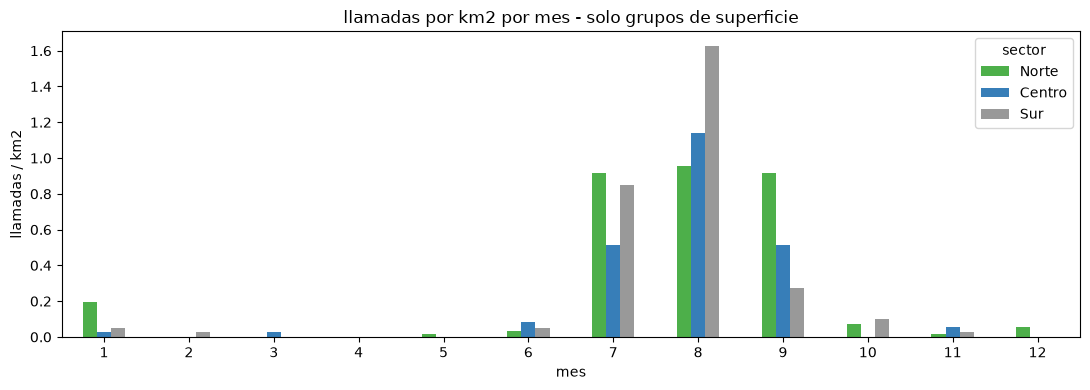

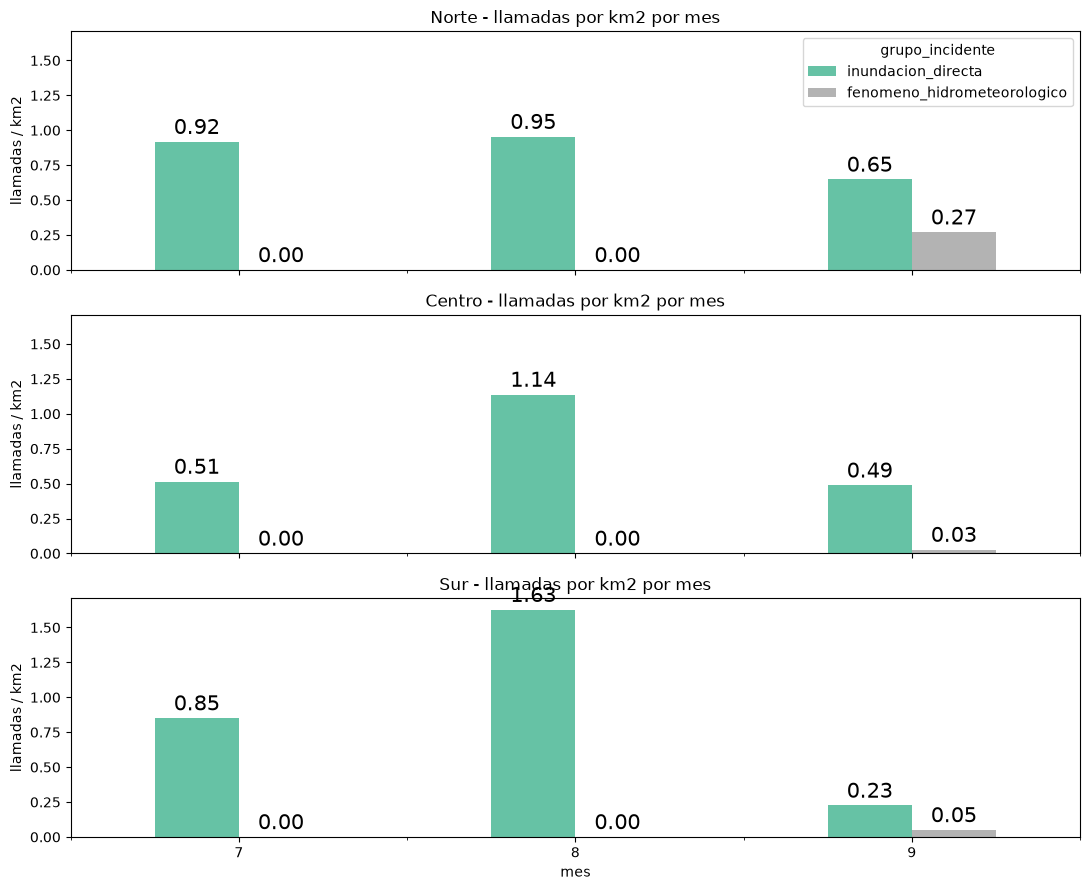

In [26]:
# llamadas por km2 por mes - solo grupos de superficie
orden_sectores = ["Norte", "Centro", "Sur"]
con_agua = con_dist[con_dist["grupo_incidente"].isin(GRUPOS_AGUA)]

mes_sector = (
    con_agua.groupby(["mes", "sector"]).size()
    .unstack(fill_value=0)
    .reindex(range(1, 13), fill_value=0)
)

# mes en el eje x, un color por sector (sumando los 3 grupos)
(mes_sector / sector_area["area_km2"]).reindex(columns=orden_sectores).plot.bar(
    figsize=(11, 4), rot=0,
    color=["#4daf4a", "#377eb8", "#999999"],
)
plt.xlabel("mes")
plt.ylabel("llamadas / km2")
plt.title("llamadas por km2 por mes - solo grupos de superficie")
plt.legend(title="sector")
plt.tight_layout()
plt.show()

# una fila por sector: mes en el eje x, un color por grupo de superficie
mes_sector_grupo = (
    con_agua.groupby(["mes", "sector", "grupo_incidente"]).size()
    .unstack(fill_value=0)
)
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True, sharey=True)
for ax, s in zip(axes, orden_sectores):
    d = mes_sector_grupo.xs(s, level="sector").reindex(range(7, 10), fill_value=0)
    (d / sector_area.loc[s, "area_km2"])[GRUPOS_AGUA].plot.bar(
        ax=ax, rot=0, colormap="Set2", legend=ax is axes[0]
    )

    # Mostrar valores encima de cada barra
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", fontsize=15, padding=2)
        
    ax.set_title(f"{s} - llamadas por km2 por mes")
    ax.set_ylabel("llamadas / km2")
axes[-1].set_xlabel("mes")
axes[0].legend(title="grupo_incidente")
plt.tight_layout()
plt.show()

### Llamadas por km² por mes y por año

Barras acumuladas: el eje x es el mes y cada barra apila los años (2018–2025). Un grid por cada grupo de superficie (`inundacion_directa` y `fenomeno_hidrometeorologico`), con un panel por sector. La densidad usa el área del sector como denominador, igual que las gráficas anteriores.

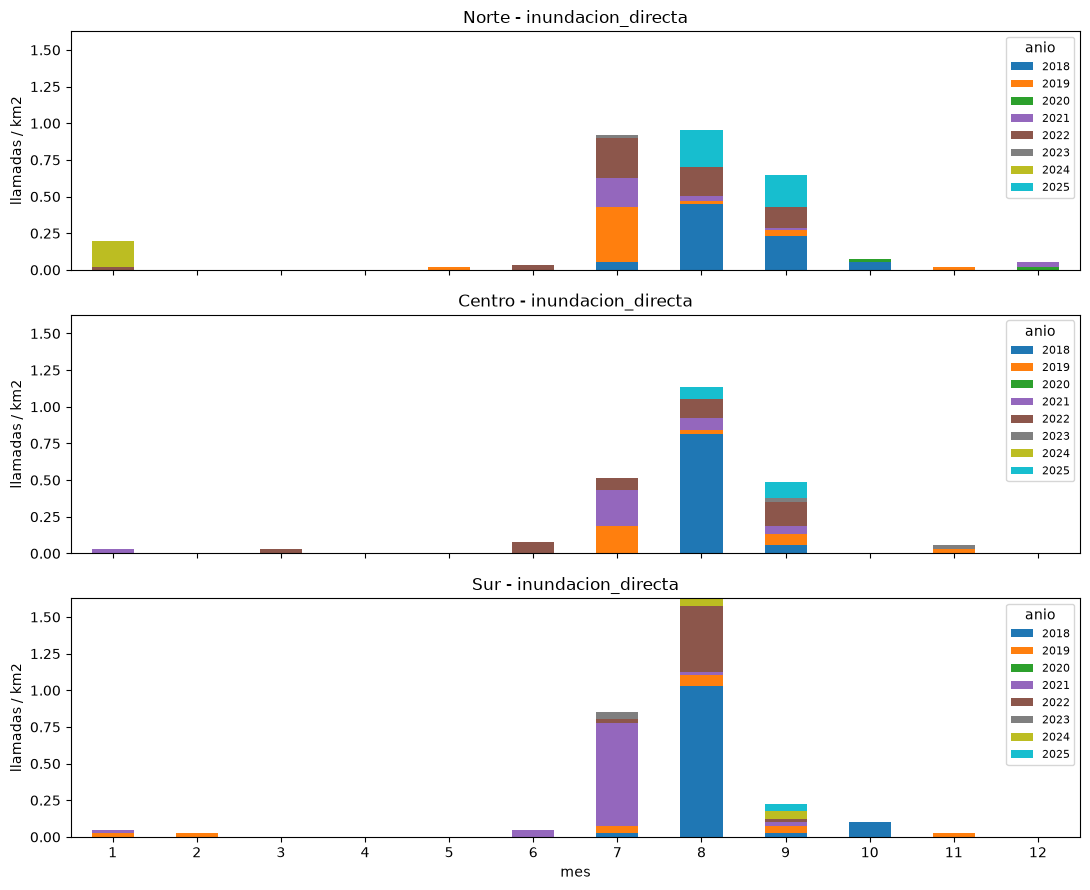

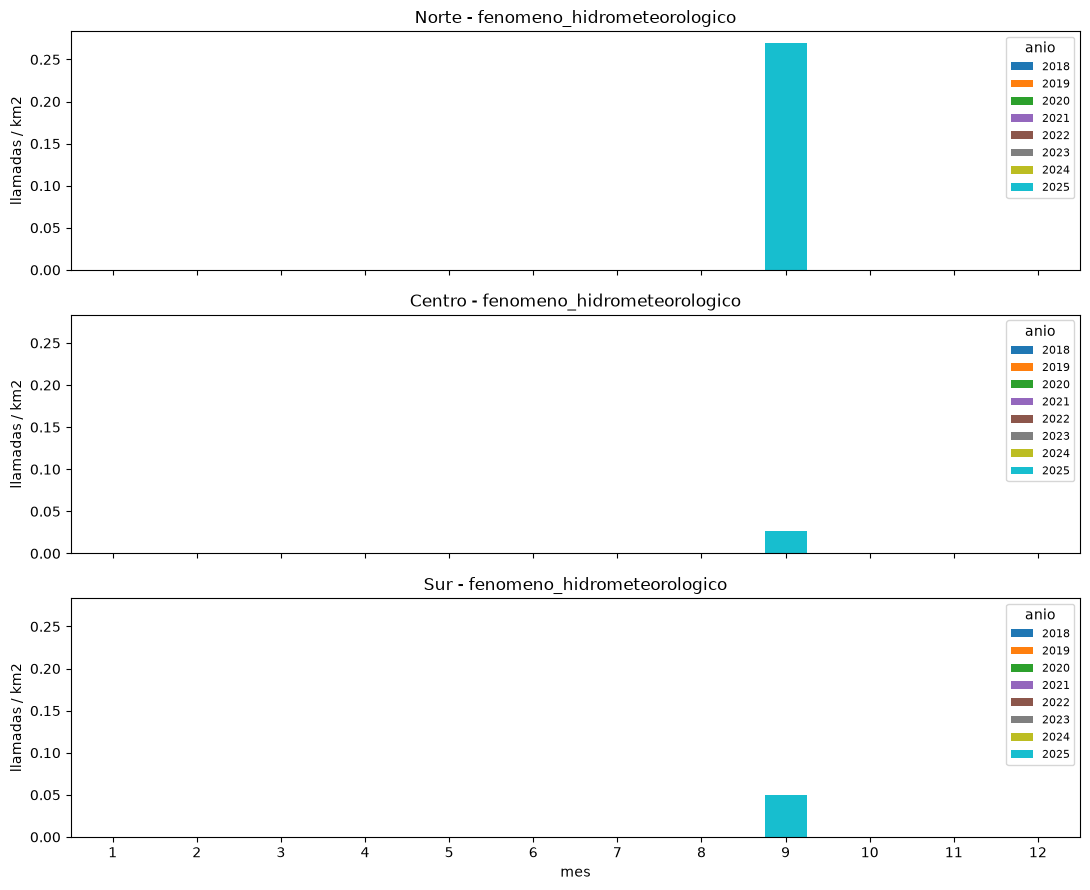

In [176]:
# llamadas por km2 por mes y por anio - barras acumuladas, un grid por grupo de
# superficie: x = mes, segmentos = anios; un panel por sector
anios = list(range(con_dist["anio"].min(), con_dist["anio"].max() + 1))

for g in GRUPOS_AGUA:
    d = con_dist[con_dist["grupo_incidente"] == g]
    fig, axes = plt.subplots(
        len(orden_sectores), 1, figsize=(11, 9), sharex=True, sharey=True
    )
    for ax, s in zip(axes, orden_sectores):
        serie = (
            d[d["sector"] == s]
            .groupby(["mes", "anio"]).size()
            .unstack(fill_value=0)
            .reindex(index=range(1, 13), columns=anios, fill_value=0)
        )
        (serie / sector_area.loc[s, "area_km2"]).plot.bar(
            ax=ax, stacked=True, rot=0, colormap="tab10",
        )
        ax.set_title(f"{s} - {g}")
        ax.set_ylabel("llamadas / km2")
        ax.legend(title="anio", fontsize=8)
    axes[-1].set_xlabel("mes")
    plt.tight_layout()
    plt.show()

Spearman llamadas vs. distancia (colonias con al menos 1 llamada):
1er_cauce    0.247
2do_cauce    0.266
3er_cauce    0.273

Spearman llamadas/km2 vs. distancia:
1er_cauce    0.140
2do_cauce    0.169
3er_cauce    0.177

Spearman llamadas vs. distancia, por sector:
  Norte: 1er_cauce=0.23  2do_cauce=0.23  3er_cauce=0.26 (n=199 colonias)
  Centro: 1er_cauce=0.16  2do_cauce=0.20  3er_cauce=0.20 (n=105 colonias)
  Sur: 1er_cauce=0.12  2do_cauce=0.19  3er_cauce=0.18 (n=92 colonias)


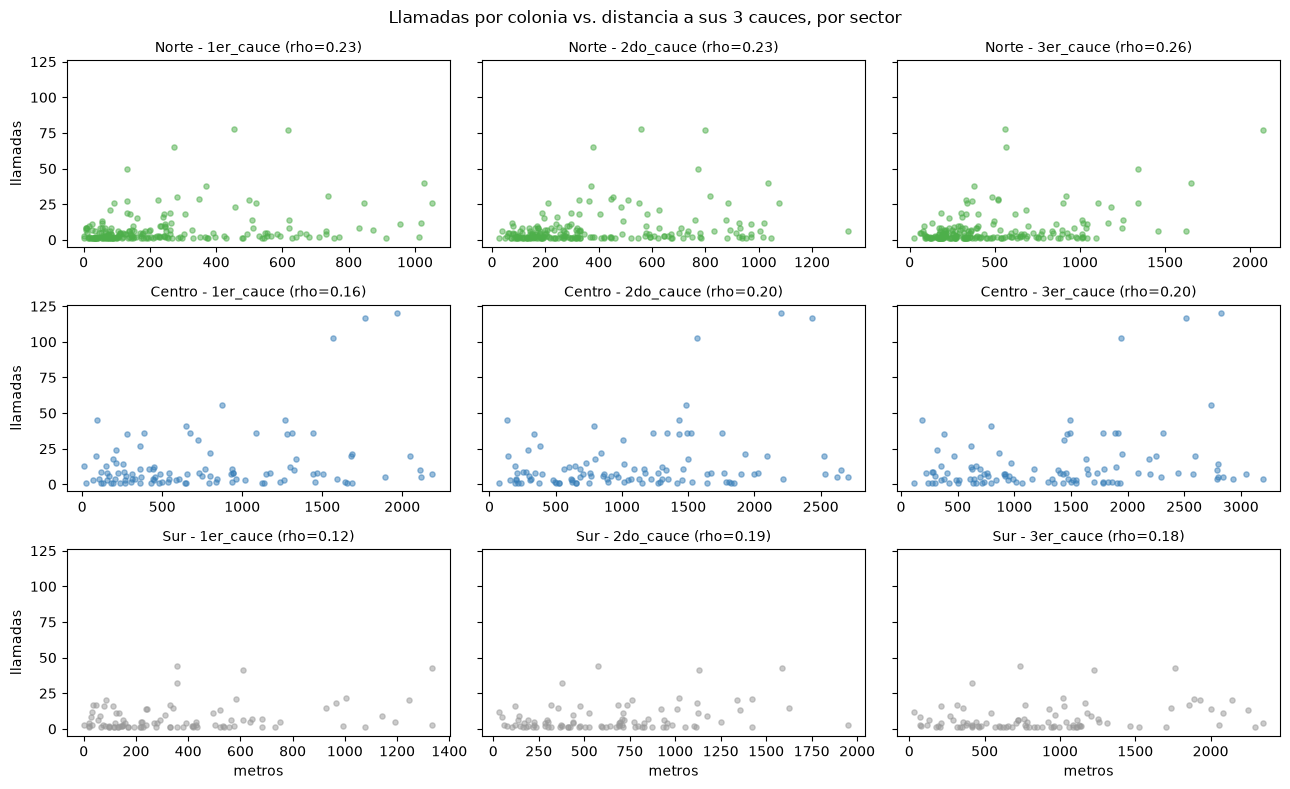

In [177]:
# un renglon por colonia: n de llamadas y sus 3 distancias (constantes por colonia)
por_colonia = (
    con_dist.groupby("colonia_id")
    .agg(
        llamadas=("colonia", "size"),
        sector=("sector", "first"),
        area_km2=("area_km2", "first"),
        **{d: (d, "first") for d in DIST + ORDEN},
    )
)
por_colonia["llamadas_km2"] = por_colonia["llamadas"] / por_colonia["area_km2"]

print("Spearman llamadas vs. distancia (colonias con al menos 1 llamada):")
print(
    por_colonia[["llamadas"] + DIST].corr(method="spearman")
    .loc["llamadas", DIST].round(3).to_string()
)
print()
print("Spearman llamadas/km2 vs. distancia:")
print(
    por_colonia[["llamadas_km2"] + DIST].corr(method="spearman")
    .loc["llamadas_km2", DIST].round(3).to_string()
)
print()
print("Spearman llamadas vs. distancia, por sector:")
for s in ["Norte", "Centro", "Sur"]:
    sub = por_colonia[por_colonia["sector"] == s]
    rho = sub[["llamadas"] + DIST].corr(method="spearman").loc["llamadas", DIST]
    print(f"  {s}: " + "  ".join(f"{d}={rho[d]:.2f}" for d in DIST)
          + f" (n={len(sub)} colonias)")

# un panel por sector: en una sola nube no se distinguen
colores_sector = {"Norte": "#4daf4a", "Centro": "#377eb8", "Sur": "#999999"}
sectores = ["Norte", "Centro", "Sur"]

fig, axes = plt.subplots(len(sectores), len(DIST), figsize=(13, 8), sharey=True)
for i, s in enumerate(sectores):
    sub = por_colonia[por_colonia["sector"] == s]
    for j, d in enumerate(DIST):
        ax = axes[i, j]
        ax.scatter(sub[d], sub["llamadas"], s=14, alpha=0.5, color=colores_sector[s])
        rho = sub["llamadas"].corr(sub[d], method="spearman")
        ax.set_title(f"{s} - {d} (rho={rho:.2f})", fontsize=10)
        if j == 0:
            ax.set_ylabel("llamadas")
        if i == len(sectores) - 1:
            ax.set_xlabel("metros")
fig.suptitle("Llamadas por colonia vs. distancia a sus 3 cauces, por sector")
plt.tight_layout()
plt.show()

**Lectura:** correlacion **positiva debil**: las colonias con mas llamadas tienden a estar *mas lejos* de los cauces (Spearman rho ~0.25-0.27 con conteo crudo, ~0.14-0.18 con llamadas/km2). Es lo contrario a la hipotesis de "el cauce atrae llamadas": lo que domina es que las llamadas se concentran en el Centro - denso, urbano y sin cauces `hl` - mas que cualquier efecto del cauce. Por sector el patron se repite (rho 0.12-0.26), o sea no es solo composicion de sectores. Caveat: solo entran colonias **con** llamadas - las 235 colonias sin cauce y sin llamadas, y las 197 con cauce y sin llamadas, no aparecen en este scatter.

### Solo Norte y Sur

El Centro esta ~3x mas lejos de la red y casi sin cauces propios - con el incluido, la correlacion mide mas "donde esta el Centro" que cualquier efecto del cauce. Se repite el cruce llamadas vs. distancia solo con **Norte y Sur**.

291 colonias Norte+Sur
Spearman llamadas vs. distancia (solo Norte y Sur):
1er_cauce    0.185
2do_cauce    0.198
3er_cauce    0.205

Spearman llamadas/km2 vs. distancia:
1er_cauce    0.114
2do_cauce    0.132
3er_cauce    0.148


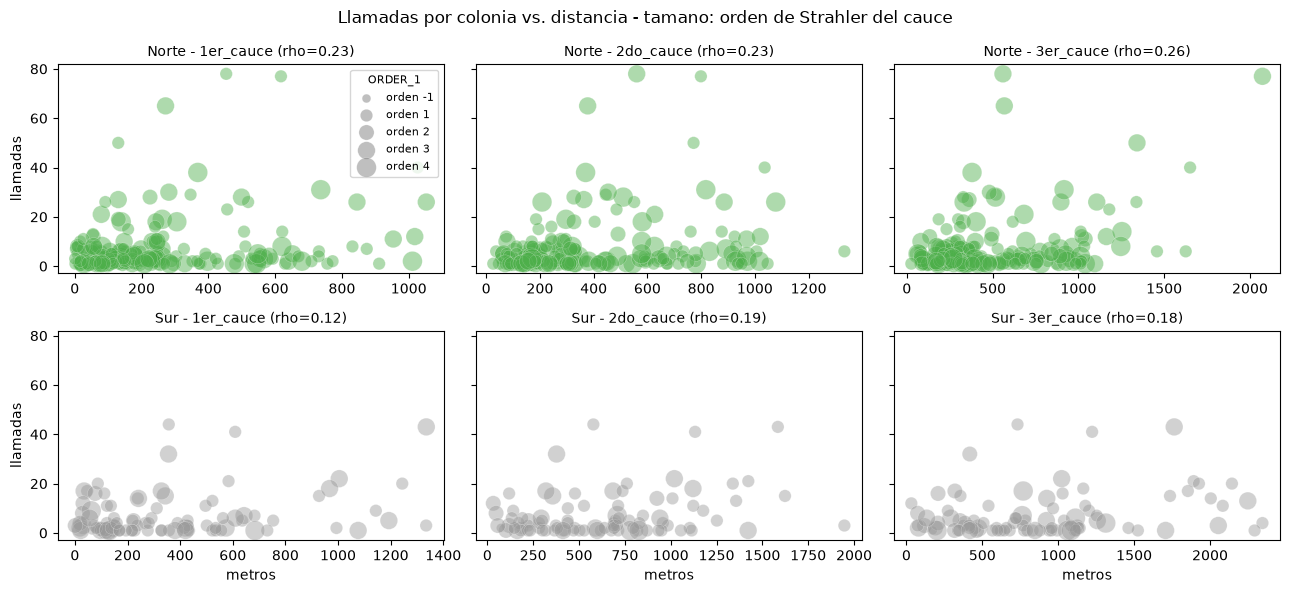

In [163]:
ns = por_colonia[por_colonia["sector"].isin(["Norte", "Sur"])]
print(f"{len(ns)} colonias Norte+Sur")

print("Spearman llamadas vs. distancia (solo Norte y Sur):")
print(
    ns[["llamadas"] + DIST].corr(method="spearman")
    .loc["llamadas", DIST].round(3).to_string()
)
print()
print("Spearman llamadas/km2 vs. distancia:")
print(
    ns[["llamadas_km2"] + DIST].corr(method="spearman")
    .loc["llamadas_km2", DIST].round(3).to_string()
)

# burbujas: el tamano es el orden de Strahler del cauce de cada columna;
# -1 (sin clasificar) queda en el tamano minimo
sectores = ["Norte", "Sur"]
fig, axes = plt.subplots(len(sectores), len(DIST), figsize=(13, 6), sharey=True)
for i, s in enumerate(sectores):
    sub = ns[ns["sector"] == s]
    for j, d in enumerate(DIST):
        ax = axes[i, j]
        orden = sub[ORDEN[j]].fillna(0).clip(lower=0)
        ax.scatter(
            sub[d], sub["llamadas"], s=(orden + 1) * 40, alpha=0.45,
            color=colores_sector[s], edgecolor="white", linewidth=0.3,
        )
        rho = sub["llamadas"].corr(sub[d], method="spearman")
        ax.set_title(f"{s} - {d} (rho={rho:.2f})", fontsize=10)
        if j == 0:
            ax.set_ylabel("llamadas")
        if i == len(sectores) - 1:
            ax.set_xlabel("metros")

# leyenda del tamano de burbuja por orden de Strahler
for val in [-1, 1, 2, 3, 4]:
    axes[0, 0].scatter(
        [], [], s=(max(val, 0) + 1) * 40, color="gray", alpha=0.5,
        edgecolor="white", linewidth=0.3, label=f"orden {val}",
    )
axes[0, 0].legend(title="ORDER_1", fontsize=8, title_fontsize=8)
fig.suptitle("Llamadas por colonia vs. distancia - tamano: orden de Strahler del cauce")
plt.tight_layout()
plt.show()

**Lectura:** sin el Centro la correlacion baja pero **no desaparece ni cambia de signo**: rho ~0.19-0.21 con conteo crudo y ~0.11-0.15 con llamadas/km2 (con Centro era ~0.25-0.27). O sea el "mas llamadas -> mas lejos del cauce" no era solo un efecto de composicion: dentro de Norte+Sur tambien se da, debilmente. La interpretacion no cambia - las llamadas no se agrupan junto a los cauces; si acaso, tienden a las colonias urbanas densas, que no son las riberenas.

## EDA: distancias a los 3 cauces - solo grupos de superficie

Se repite el EDA de distancias pero solo con las llamadas de `inundacion_directa` y `fenomeno_hidrometeorologico` (`con_agua`) — los grupos que mostraron el patron estacional jul-sep. `ahogamiento_acuaticos` queda fuera por ser mayoritariamente costero (Kino / Miguel Aleman) y sin hotspot urbano. Distancias medias distintas a las de todos los grupos serian senal de que estas llamadas caen en colonias particularmente cercanas (o lejanas) a los cauces.

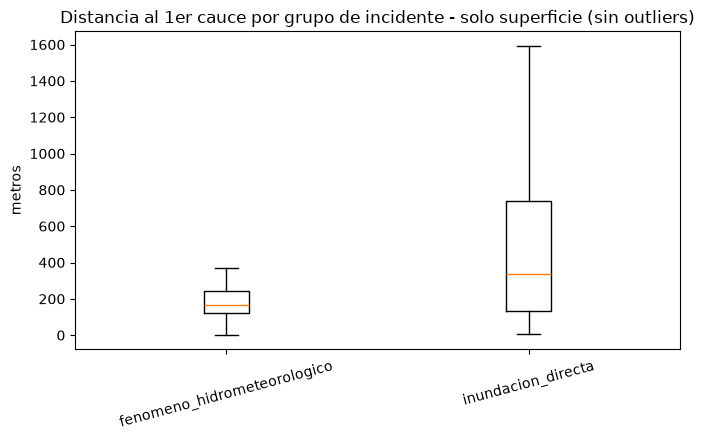

Kruskal-Wallis (1er_cauce ~ grupo, solo superficie): H=7.9, p=0.00497


In [164]:
# mismo boxplot de la celda 30 pero solo con los grupos de superficie
fig, ax = plt.subplots(figsize=(7, 4.5))
orden_g = (
    con_agua.groupby("grupo_incidente")["1er_cauce"].median()
    .sort_values().index
)
datos = [
    con_agua.loc[con_agua["grupo_incidente"] == g, "1er_cauce"]
    for g in orden_g
]
ax.boxplot(datos, tick_labels=orden_g, showfliers=False)
ax.set_ylabel("metros")
ax.set_title(
    "Distancia al 1er cauce por grupo de incidente"
    " - solo superficie (sin outliers)"
)
ax.tick_params(axis="x", labelrotation=15)
plt.tight_layout()
plt.show()

from scipy.stats import kruskal
H, p = kruskal(*datos)
print(f"Kruskal-Wallis (1er_cauce ~ grupo, solo superficie): H={H:.1f}, p={p:.3g}")

        1er_cauce_mean  1er_cauce_median  2do_cauce_mean  2do_cauce_median  3er_cauce_mean  3er_cauce_median  llamadas  colonias
sector                                                                                                                          
Centro          1003.0             796.0          1380.0            1343.0          1780.0            1789.0        87        38
Norte            274.0             225.0           427.0             363.0           536.0             363.0       177        68
Sur              573.0             465.0           912.0             925.0          1168.0            1073.0       120        41


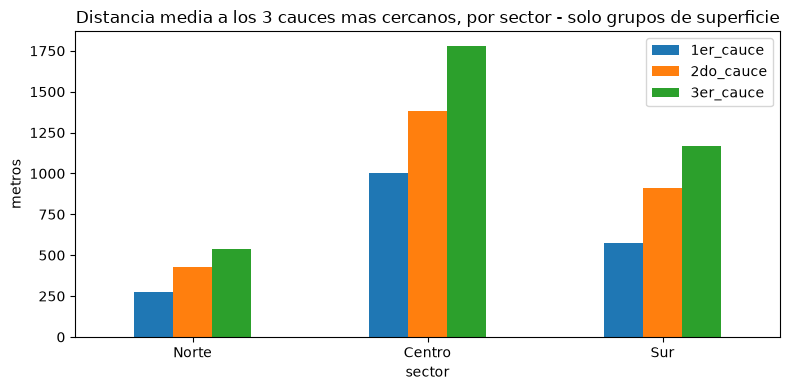

In [170]:
# misma grafica por sector de la celda 32 pero solo grupos de superficie
resumen_sector_agua = con_agua.groupby("sector")[DIST].agg(["mean", "median"]).round(0)
resumen_sector_agua.columns = [f"{d}_{m}" for d, m in resumen_sector_agua.columns]
resumen_sector_agua["llamadas"] = con_agua["sector"].value_counts()
resumen_sector_agua["colonias"] = con_agua.groupby("sector")["colonia_id"].nunique()
print(resumen_sector_agua.to_string())

fig, ax = plt.subplots(figsize=(8, 4))
con_agua.groupby("sector")[DIST].mean().reindex(["Norte", "Centro", "Sur"]).plot.bar(
    ax=ax, rot=0
)
ax.set_ylabel("metros")
ax.set_title(
    "Distancia media a los 3 cauces mas cercanos, por sector"
    " - solo grupos de superficie"
)
plt.tight_layout()
plt.show()

In [171]:
# comparativo por sector como en la libreta 06: km de cauce por km2 vs.
# llamadas por km2 (conteo de con_dist, ya con las equivalencias aplicadas)

### Ahogamiento_acuaticos por separado (solo ciudad)

Como `ahogamiento_acuaticos` quedo fuera de los grupos de superficie, aqui se analiza por separado pero **solo dentro de la ciudad**: `con_dist` solo trae colonias urbanas emparejadas, asi que Bahia de Kino / Miguel Aleman y demas localidades costeras ya quedan excluidas. Color por `tipo_incidente`.

12 llamadas de ahogamiento_acuaticos dentro de la ciudad
tipo_incidente
AHOGAMIENTO    12


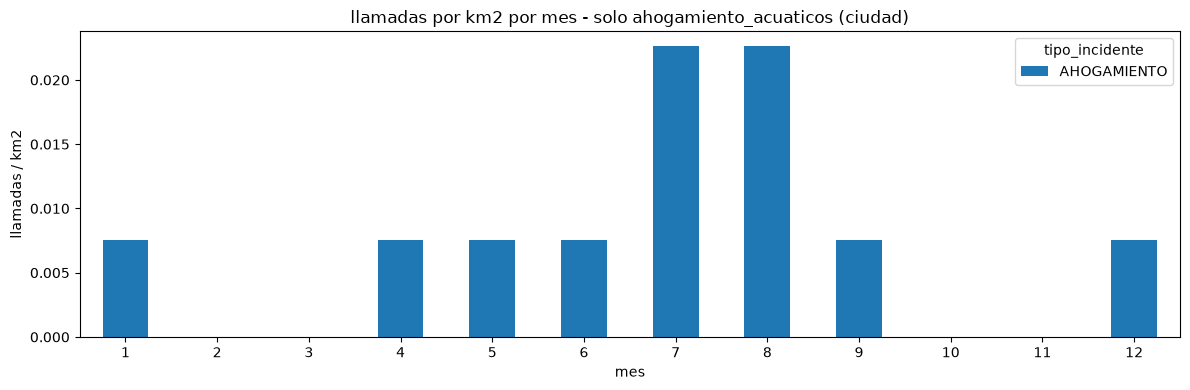

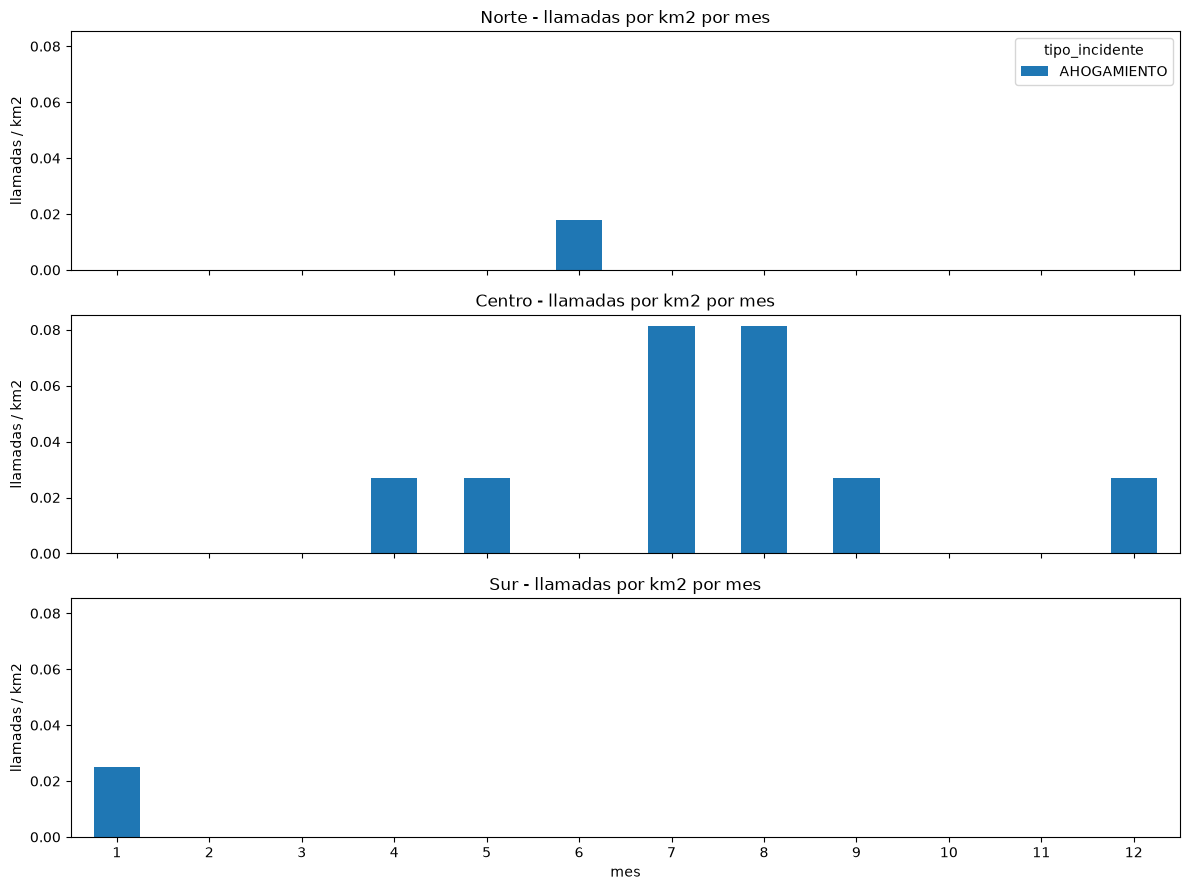

In [172]:
# llamadas por km2 por mes - solo ahogamiento_acuaticos dentro de la ciudad
# (con_dist solo trae colonias urbanas: Kino / Miguel Aleman quedan fuera)
ahoga = con_dist[con_dist["grupo_incidente"] == "ahogamiento_acuaticos"]
print(f"{len(ahoga)} llamadas de ahogamiento_acuaticos dentro de la ciudad")
print(ahoga["tipo_incidente"].value_counts().to_string())

mes_tipo = (
    ahoga.groupby(["mes", "tipo_incidente"]).size()
    .unstack(fill_value=0)
    .reindex(range(1, 13), fill_value=0)
)

# mes en el eje x, un color por tipo de incidente (toda la ciudad)
(mes_tipo / sector_area["area_km2"].sum()).plot.bar(
    figsize=(12, 4), rot=0, colormap="tab10"
)
plt.xlabel("mes")
plt.ylabel("llamadas / km2")
plt.title("llamadas por km2 por mes - solo ahogamiento_acuaticos (ciudad)")
plt.legend(title="tipo_incidente")
plt.tight_layout()
plt.show()

# una fila por sector: mes en el eje x, un color por tipo de incidente
mes_sector_tipo = (
    ahoga.groupby(["mes", "sector", "tipo_incidente"]).size()
    .unstack(fill_value=0)
)
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True, sharey=True)
for ax, s in zip(axes, orden_sectores):
    if s in mes_sector_tipo.index.get_level_values("sector"):
        d = mes_sector_tipo.xs(s, level="sector").reindex(
            range(1, 13), fill_value=0
        )
    else:
        d = pd.DataFrame(0, index=range(1, 13),
                         columns=mes_sector_tipo.columns)
    (d / sector_area.loc[s, "area_km2"]).plot.bar(
        ax=ax, rot=0, colormap="tab10", legend=ax is axes[0]
    )
    ax.set_title(f"{s} - llamadas por km2 por mes")
    ax.set_ylabel("llamadas / km2")
axes[-1].set_xlabel("mes")
axes[0].legend(title="tipo_incidente")
plt.tight_layout()
plt.show()